# RQ3 Validity

Reproduces every number of the validity section of the paper (`tables/rq3.tex`, the human-study text of section 5 and 4.5). Run all cells top to bottom; then `sh sync_paper.sh`.

**Inputs:** `../outputs/results` (evaluation.json per run, via `results_loader`), `../survey/responses.csv` (downloaded from the response sheet; set `REFRESH = False` to use the cached snapshot), `../survey/private/key.json` (git-ignored; maps survey item -> condition and source run).

**Mechanical validity (m-valid).** A test case is m-valid if its UTMOS is at least the lower bound of the central 95% interval of the UTMOS of the task's original audio (`results_loader.validity_threshold`, 2.5th percentile; 4.26 for Harvard, 4.03 for commands). M-valid / found is computed over the found test cases (ASR: WER > 0; intent: target hit).

**Human study.** Per rating: realism (1-5), heard as the original (`understood_match`), plausible transcription. Participants are excluded if they hear < 75% of the original recordings as the shown text (attention check) or repeat items; ratings with 0 plays are dropped. Human-confirmed success = heard as original (yes) and SUT transcription not plausible (no). The unit of analysis is the audio (mean over its ratings).

**Tests.** Reference method (GATAS on ASR, GATAS_llm on intent) vs SMACK and ALIF: one-sided Mann-Whitney per configuration and measure, Holm over the two baselines, Cohen's d (bullets: small <= 0.5, medium <= 1, large > 1). Reference vs original audio: two-sided, uncorrected. Agreement of UTMOS / m-valid with realism: Spearman with bootstrap 95% CI, ceiling from split-half reliability (Spearman-Brown).


## Mechanical validity


In [1]:
ROOT = "../outputs/results"
import pandas as pd
from results_loader import MODELS, load_all, task_thresholds, asr_found, intent_hit
import paper_tables as pt
asr2, intent2 = load_all(ROOT)
thr2 = task_thresholds(asr2, intent2)
print("m-valid UTMOS thresholds per task:", {t: round(v, 3) for t, v in thr2.items()})

METHODS_TAB = ["GATAS", "GATAS_llm", "Waveform", "SMACK_untargeted", "SMACK", "ALIF", "PGD"]
rows = []
for task, data, found in (("ASR", asr2, asr_found), ("Intent", intent2, intent_hit)):
    for model in MODELS:
        for m in METHODS_TAB:
            rs = data[model].get(m)
            if rs:
                f = [r for r in rs if found(r)]
                k = sum(r["utmos"] >= thr2[task] for r in f)
                rows.append({"task": task, "model": model, "method": m, "n": len(rs), "found": len(f), "m_valid": k,
                             "m_valid_of_found_%": 100 * k / len(f) if f else float("nan")})
frame = pd.DataFrame(rows)
frame.round(3).to_csv("_tables/rq3_values.csv", index=False)
display(frame.round(1))

def validity_cell(task, model, m):
    r = frame[(frame.task == task) & (frame.model == model) & (frame.method == m)]
    return f"{r['m_valid_of_found_%'].iloc[0]:.1f} ({r.m_valid.iloc[0]}/{r.found.iloc[0]})" if len(r) and r.found.iloc[0] else "--"

mvalid_rows = []
for m in METHODS_TAB:
    cells = [validity_cell(task, model, m) for model in MODELS for task in ("ASR", "Intent")]
    mvalid_rows.append(f"{pt.TEX_NAME[m]} & " + " & ".join(cells) + r" \\")


m-valid UTMOS thresholds per task: {'ASR': 4.262, 'Intent': 4.031}


/home/weissl/Projects/GATAS/analysis/results_loader.py:32: UserWarning: No PGD results for harvard / wav2vec2-large in ../outputs/results
  warnings.warn(f"No {method} results for {dataset} / {asr_model} in {results_root}")
/home/weissl/Projects/GATAS/analysis/results_loader.py:32: UserWarning: No PGD results for commands / wav2vec2-large in ../outputs/results
  warnings.warn(f"No {method} results for {dataset} / {asr_model} in {results_root}")


,task,model,method,n,found,m_valid,m_valid_of_found_%
0,ASR,whisper-tiny,GATAS,71,63,37,58.7
1,ASR,whisper-tiny,Waveform,71,71,0,0.0
2,ASR,whisper-tiny,SMACK_untargeted,72,65,1,1.5
3,ASR,whisper-tiny,SMACK,72,50,2,4.0
4,ASR,whisper-tiny,ALIF,72,72,0,0.0
5,ASR,whisper-tiny,PGD,72,72,0,0.0
6,ASR,wav2vec2-large,GATAS,92,86,50,58.1
7,ASR,wav2vec2-large,Waveform,92,92,0,0.0
8,ASR,wav2vec2-large,SMACK_untargeted,92,78,5,6.4
9,ASR,wav2vec2-large,SMACK,92,68,1,1.5


## Human study: data and exclusions


In [2]:
import json, os, urllib.request
import numpy as np
from scipy import stats

SHEET = "1gqpJs8xKk-GUQ6TEnX8SrmjrWkQGdU6OqM8bKmMDTWk"
RESPONSES = "../survey/responses.csv"
ATTENTION = 75  # min. share [%] of clean recordings that must be heard as the shown text
REFRESH = True  # True: download the current sheet (the paper numbers refer to the cached snapshot)
if REFRESH:
    try:
        urllib.request.urlretrieve(f"https://docs.google.com/spreadsheets/d/{SHEET}/export?format=csv", RESPONSES)
    except Exception:
        print("sheet not reachable, using the cached", RESPONSES)
raw = pd.read_csv(RESPONSES)
# some rows lack the headphones column (item sits in 'headphones'): shift them back into the header layout
shifted = raw.headphones.astype(str).str.fullmatch(r"i[0-9a-f]{10}")
if shifted.any():
    cols = list(raw.columns[raw.columns.get_loc("headphones"):])
    raw.loc[shifted, cols] = np.column_stack([np.full(shifted.sum(), np.nan), raw.loc[shifted, cols[:-1]].to_numpy()])
    for c in ("order", "realism", "plays", "seconds"):
        raw[c] = pd.to_numeric(raw[c])
    print(f"realigned {shifted.sum()} rows without the headphones column")
key = json.load(open("../survey/private/key.json"))

def item_row(item):
    k = key[item]
    task = "ASR" if k["cell"].endswith("asr") else "Intent"
    ev = json.load(open(os.path.join("..", os.path.dirname(k["source"]), "evaluation.json")))
    clean = k["condition"] == "clean"
    method = "Clean" if clean else {"ours": "GATAS" if task == "ASR" else "GATAS_llm"}.get(k["condition"], k["condition"])
    return {"item": item, "task": task, "model": ev["asr_model"], "method": method,
            "utmos": ev["scores"]["UTMOS_ORIGINAL" if clean else "UTMOS"]}

items = pd.DataFrame([item_row(i) for i in key]).set_index("item")
items["m_valid"] = items.utmos >= items.task.map(thr2)
d = raw.join(items, on="item")

participants = d.groupby("participant").apply(lambda g: pd.Series({
    "ratings": len(g), "distinct items": g.item.nunique(),
    "clean heard as shown [%]": 100 * (g[g.method == "Clean"].understood_match == "yes").mean(),
    "clean transcript plausible [%]": 100 * (g[g.method == "Clean"].plausible_transcription == "yes").mean(),
    "not played": int((g.plays < 1).sum()), "median seconds": g.seconds.median(), "realism sd": g.realism.std()}), include_groups=False)
participants["valid"] = (participants["clean heard as shown [%]"] >= ATTENTION) & (participants["distinct items"] == participants.ratings)
ok = d[d.participant.isin(participants.index[participants.valid]) & (d.plays >= 1)]
print(f"valid participants: {participants.valid.sum()} of {len(participants)}; ratings kept: {len(ok)} of {len(d)}; "
      f"audios rated: {ok.item.nunique()} of {len(items)}")

valid participants: 133 of 140; ratings kept: 4132 of 4544; audios rated: 542 of 542


## Realism


In [3]:
def boot_spearman(x, y, n_boot=5000, seed=0):
    rng = np.random.default_rng(seed)
    b = []
    for _ in range(n_boot):
        j = rng.integers(0, len(x), len(x))
        if np.ptp(x[j]) and np.ptp(y[j]):
            b.append(stats.spearmanr(x[j], y[j])[0])
    return np.quantile(b, [0.025, 0.975])

def rho(df, col):
    x, y = df[col].to_numpy(float), df.realism.to_numpy(float)
    if len(df) < 5 or not np.ptp(x):
        return np.nan, np.nan, np.nan
    return (stats.spearmanr(x, y)[0], *boot_spearman(x, y))

# unit of analysis: the audio (mean over its ratings), so that audios with more ratings do not weigh more
ok = ok.assign(heard=ok.understood_match == "yes", confirmed=(ok.understood_match == "yes") & (ok.plausible_transcription == "no"))
per_audio = ok.groupby("item").agg(ratings=("realism", "size"), realism=("realism", "mean"), heard=("heard", "mean"), confirmed=("confirmed", "mean")).join(items)
REF = {"ASR": "GATAS", "Intent": "GATAS_llm"}
per_audio["reference"] = per_audio.method == per_audio.task.map(REF)
tc = per_audio[per_audio.method != "Clean"]

# noise ceiling: split-half reliability (Spearman-Brown) of the per-audio mean realism
rng = np.random.default_rng(0)
rel = []
for _ in range(200):
    a, b = [], []
    for _, g in ok.groupby("item"):
        if len(g) >= 2:
            r = rng.permutation(g.realism.to_numpy(float)); a.append(r[: len(r) // 2].mean()); b.append(r[len(r) // 2:].mean())
    r = stats.spearmanr(a, b)[0]; rel.append(2 * r / (1 + r))
print(f"split-half reliability of the mean realism per audio: {np.mean(rel):.2f}; ratings per audio: median {per_audio.ratings.median():.0f}, min {per_audio.ratings.min()}")

groups = [("All audios", per_audio), ("Test cases", tc), ("Original audio", per_audio[per_audio.method == "Clean"]),
          ("Reference method", per_audio[per_audio.reference]), ("SMACK", per_audio[per_audio.method == "SMACK"]), ("ALIF", per_audio[per_audio.method == "ALIF"])]
for (task, model), g in tc.groupby(["task", "model"]):
    groups.append((f"Test cases, {task}, {model}", g))
rows = []
for scope, df in groups:
    row = {"scope": scope, "audios": len(df)}
    for name, col in (("UTMOS", "utmos"), ("m-valid", "m_valid")):
        r, lo, hi = rho(df.assign(**{col: df[col].astype(float)}), col)
        row.update({f"{name} rho": r, f"{name} CI low": lo, f"{name} CI high": hi})
    rows.append(row)
corr = pd.DataFrame(rows)
corr.round(2).to_csv("_tables/rq3_human_realism.csv", index=False)
display(corr.round(2))

# does m-valid separate realistic from unrealistic audio? (one-sided Mann-Whitney on the per-audio realism)
rows = []
for scope, df in (("Test cases", tc), ("Reference method", tc[tc.reference])):
    a, b = df[df.m_valid].realism, df[~df.m_valid].realism
    mw = stats.mannwhitneyu(a, b, alternative="greater")
    rows.append({"scope": scope, "m-valid audios": len(a), "other audios": len(b), "mean realism m-valid": a.mean(), "mean realism other": b.mean(),
                 "p": mw.pvalue, "Cliff delta": 2 * mw.statistic / (len(a) * len(b)) - 1})
mvalid_split = pd.DataFrame(rows)
mvalid_split.round(4).to_csv("_tables/rq3_human_mvalid_split.csv", index=False)
display(mvalid_split.round(3))


split-half reliability of the mean realism per audio: 0.82; ratings per audio: median 6, min 2


,scope,audios,UTMOS rho,UTMOS CI low,UTMOS CI high,m-valid rho,m-valid CI low,m-valid CI high
0,All audios,542,0.77,0.73,0.80,0.68,0.63,0.72
1,Test cases,402,0.70,0.64,0.75,0.52,0.45,0.59
2,Original audio,140,-0.10,-0.27,0.07,0.02,-0.14,0.17
3,Reference method,140,0.39,0.23,0.51,0.12,-0.05,0.28
4,SMACK,124,0.56,0.42,0.67,0.14,-0.05,0.28
5,ALIF,138,0.38,0.23,0.51,NaN,NaN,NaN
6,"Test cases, ASR, wav2vec2-large",105,0.70,0.57,0.78,0.58,0.46,0.68
7,"Test cases, ASR, whisper-tiny",105,0.75,0.65,0.83,0.51,0.36,0.64
8,"Test cases, Intent, wav2vec2-large",87,0.61,0.45,0.74,0.56,0.40,0.69
9,"Test cases, Intent, whisper-tiny",105,0.69,0.57,0.79,0.55,0.40,0.67


,scope,m-valid audios,other audios,mean realism m-valid,mean realism other,p,Cliff delta
0,Test cases,98,304,3.690,2.462,0.000,0.699
1,Reference method,95,45,3.713,3.511,0.078,0.149


,task,model,method,ratings,mean,CI low,CI high
1,ASR,wav2vec2-large,Clean,258,4.36,4.24,4.46
2,ASR,wav2vec2-large,GATAS,259,4.08,3.95,4.20
3,ASR,wav2vec2-large,SMACK,255,2.22,2.05,2.39
0,ASR,wav2vec2-large,ALIF,257,2.61,2.44,2.77
5,ASR,whisper-tiny,Clean,258,4.42,4.31,4.53
6,ASR,whisper-tiny,GATAS,256,4.06,3.93,4.20
7,ASR,whisper-tiny,SMACK,259,2.44,2.25,2.61
4,ASR,whisper-tiny,ALIF,259,2.69,2.53,2.85
9,Intent,wav2vec2-large,Clean,260,4.13,3.99,4.25
10,Intent,wav2vec2-large,GATAS_llm,257,3.52,3.36,3.68


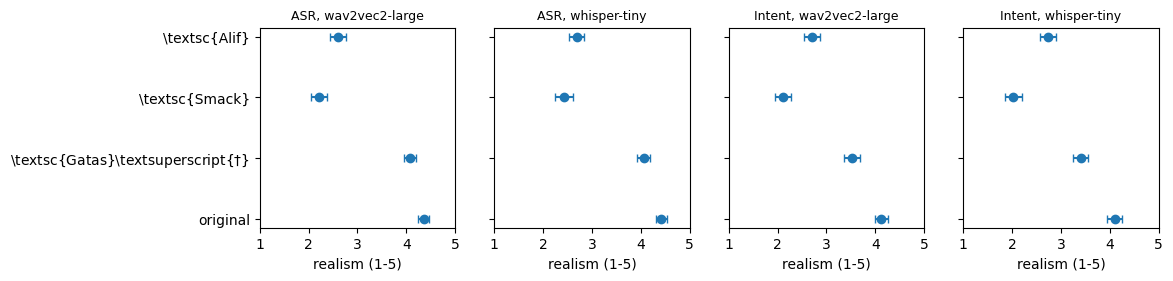

In [4]:
# human realism rating (1-5) per configuration (task x model) and method, mean with bootstrap 95% CI over the ratings
import matplotlib.pyplot as plt
from results_loader import tex_name

def boot_mean(x, n_boot=5000, seed=0):
    rng = np.random.default_rng(seed)
    return np.quantile([x[rng.integers(0, len(x), len(x))].mean() for _ in range(n_boot)], [0.025, 0.975])

R_ORDER = ["Clean", "GATAS", "GATAS_llm", "SMACK", "ALIF"]
rows = []
for (task, model, method), g in ok.groupby(["task", "model", "method"]):
    x = g.realism.to_numpy(float)
    lo, hi = boot_mean(x)
    rows.append({"task": task, "model": model, "method": method, "ratings": len(x), "mean": x.mean(), "CI low": lo, "CI high": hi})
mean_realism = pd.DataFrame(rows).sort_values(["task", "model", "method"], key=lambda s: s.map(R_ORDER.index) if s.name == "method" else s)
mean_realism.round(2).to_csv("_tables/rq3_human_realism_by_method.csv", index=False)
display(mean_realism.round(2))

configs = sorted({(t, m) for t, m in zip(mean_realism.task, mean_realism.model)}, key=lambda c: (c[0], c[1]))
fig, axes = plt.subplots(1, len(configs), figsize=(2.9 * len(configs), 2.6), sharex=True, sharey=True, squeeze=False)
for ax, (task, model) in zip(axes[0], configs):
    v = mean_realism[(mean_realism.task == task) & (mean_realism.model == model)].reset_index(drop=True)
    ax.errorbar(v["mean"], range(len(v)), xerr=[v["mean"] - v["CI low"], v["CI high"] - v["mean"]], fmt="o", capsize=3, color="tab:blue")
    ax.set_yticks(range(len(v))); ax.set_yticklabels(["original" if m == "Clean" else tex_name(m) for m in v.method]); ax.invert_yaxis()
    ax.set_xlim(1, 5); ax.set_title(f"{task}, {model}", fontsize=9); ax.set_xlabel("realism (1-5)")
plt.savefig("_figures/rq3_human_realism.pdf", bbox_inches="tight")


## Human validity


In [5]:
import matplotlib.pyplot as plt
from results_loader import tex_name

ORDER = ["Clean", "GATAS", "GATAS_llm", "SMACK", "ALIF"]
ANSWERS = ["yes", "unsure", "no"]
rows = []
for (task, method), g in ok.groupby(["task", "method"]):
    n, k = len(g), int((g.understood_match == "yes").sum())
    rows.append({"task": task, "method": method, "ratings": n,
                 **{a: 100 * (g.understood_match == a).mean() for a in ANSWERS},
                 "strict [%]": 100 * k / n,
                 "lenient [%]": 100 * (g.understood_match != "no").mean()})
validity = pd.DataFrame(rows).sort_values(["task", "method"], key=lambda s: s.map(ORDER.index) if s.name == "method" else s)
validity.round(1).to_csv("_tables/rq3_human_validity.csv", index=False)
display(validity.round(1))

,task,method,ratings,yes,unsure,no,strict [%],lenient [%]
1,ASR,Clean,516,97.9,0.6,1.6,97.9,98.4
2,ASR,GATAS,515,87.8,4.5,7.8,87.8,92.2
3,ASR,SMACK,514,27.8,10.5,61.7,27.8,38.3
0,ASR,ALIF,516,44.8,13.6,41.7,44.8,58.3
5,Intent,Clean,519,97.1,0.8,2.1,97.1,97.9
6,Intent,GATAS_llm,515,31.1,8.3,60.6,31.1,39.4
7,Intent,SMACK,519,17.9,10.8,71.3,17.9,28.7
4,Intent,ALIF,518,61.8,11.2,27.0,61.8,73.0


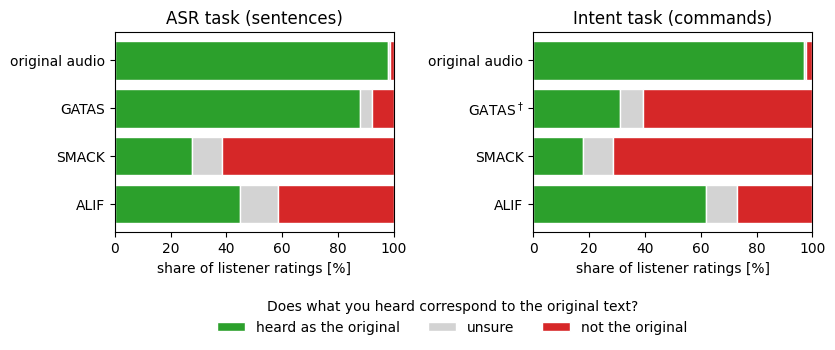

In [6]:
COLORS = {"yes": "tab:green", "unsure": "lightgray", "no": "tab:red"}
LEGEND = {"yes": "heard as the original", "unsure": "unsure", "no": "not the original"}
NAMES = {"Clean": "original audio", "GATAS": "GATAS", "GATAS_llm": "GATAS$^\\dagger$", "SMACK": "SMACK", "ALIF": "ALIF"}
fig, axes = plt.subplots(1, 2, figsize=(9, 2.6), sharex=True, gridspec_kw={"wspace": 0.5})
for ax, task, title in zip(axes, ("ASR", "Intent"), ("ASR task (sentences)", "Intent task (commands)")):
    v = validity[validity.task == task].reset_index(drop=True)
    left = np.zeros(len(v))
    for a in ANSWERS:
        ax.barh(range(len(v)), v[a], left=left, color=COLORS[a], label=LEGEND[a], edgecolor="white")
        left += v[a].to_numpy()
    ax.set_yticks(range(len(v))); ax.set_yticklabels([NAMES[m] for m in v.method]); ax.invert_yaxis()
    ax.set_xlim(0, 100); ax.set_xlabel("share of listener ratings [%]"); ax.set_title(title)
fig.legend(*axes[0].get_legend_handles_labels(), ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1), frameon=False,
           title="Does what you heard correspond to the original text?")
plt.savefig("_figures/rq3_human_validity.pdf", bbox_inches="tight")

In [7]:
from stats_utils import holm
BASE = ["SMACK", "ALIF"]
MEAS = {"realism": "Realism (1--5)", "heard": "Heard as the original [\\%]", "confirmed": "Human-confirmed success [\\%]"}

def cohen_d(x, y):
    sd = np.sqrt(((len(x) - 1) * x.var(ddof=1) + (len(y) - 1) * y.var(ddof=1)) / (len(x) + len(y) - 2))
    return (x.mean() - y.mean()) / sd if sd > 0 else np.nan

rows = []
for (task, model), g in per_audio.groupby(["task", "model"]):
    ref = g[g.method == REF[task]]
    for meas in MEAS:
        scale = 1 if meas == "realism" else 100
        vals = {m: g[g.method == m][meas].to_numpy(float) for m in ["Clean", REF[task], *BASE]}
        ps = [stats.mannwhitneyu(vals[REF[task]], vals[b], alternative="greater").pvalue for b in BASE]
        ph = holm(ps)
        p_clean = stats.mannwhitneyu(vals[REF[task]], vals["Clean"], alternative="two-sided").pvalue
        for m, v in vals.items():
            row = {"task": task, "model": model, "measure": meas, "method": m, "audios": len(v), "value": scale * v.mean(),
                   "CI low": scale * np.quantile([v[rng.integers(0, len(v), len(v))].mean() for _ in range(2000)], 0.025),
                   "CI high": scale * np.quantile([v[rng.integers(0, len(v), len(v))].mean() for _ in range(2000)], 0.975)}
            if m in BASE:
                i = BASE.index(m)
                row.update({"p_holm": ph[i], "d": cohen_d(vals[REF[task]], v), "ref_better": bool(ph[i] < 0.05)})
            if m == REF[task]:
                row.update({"p_vs_clean": p_clean, "d_vs_clean": cohen_d(v, vals["Clean"])})
            rows.append(row)
tests = pd.DataFrame(rows)
tests.round(4).to_csv("_tables/rq3_human_tests.csv", index=False)
display(tests[tests.method != "Clean"].round(3).pivot_table(index=["measure", "task", "model"], columns="method", values=["value", "p_holm", "d"]).round(3))
print("reference vs original audio (two-sided, uncorrected):")
display(tests[tests.method.isin(REF.values())][["task", "model", "measure", "value", "p_vs_clean", "d_vs_clean"]].round(4))
print("reference significantly better than a baseline:", int(tests.ref_better.sum()), "of", int(tests.ref_better.notna().sum()))
print("effect sizes of the significant ones:", tests[tests.ref_better == True].d.pipe(lambda s: {"large": int((s > 1).sum()), "medium": int(((s > .5) & (s <= 1)).sum()), "small": int((s <= .5).sum())}))

import paper_tables as pt
CONF = [("whisper-tiny", "ASR"), ("whisper-tiny", "Intent"), ("wav2vec2-large", "ASR"), ("wav2vec2-large", "Intent")]
def tcell(meas, model, task, kind):
    method = "Clean" if kind == "Clean" else REF[task] if kind == "ours" else kind
    r = tests[(tests.measure == meas) & (tests.model == model) & (tests.task == task) & (tests.method == method)]
    if not len(r): return "--"
    r = r.iloc[0]
    text = f"{r.value:.2f}" if meas == "realism" else f"{r.value:.1f}"
    return text + (pt.bullet(r.d) if kind in BASE and r.ref_better else "")
def mcell(task, model, kind):
    method = REF[task] if kind == "ours" else kind
    r = frame[(frame.task == task) & (frame.model == model) & (frame.method == method)]
    return f"{r['m_valid_of_found_%'].iloc[0]:.1f}" if len(r) and r.found.iloc[0] else "--"

MV = [("ours", "Ours"), ("Waveform", r"\wv"), ("SMACK_untargeted", r"\smack$^\ddagger$"), ("SMACK", r"\smack"), ("ALIF", r"\alif"), ("PGD", r"\pgd")]
HU = [("Clean", "Orig."), ("ours", "Ours"), ("SMACK", r"\smack"), ("ALIF", r"\alif")]
HUMAN = [("realism", "Realism (1--5)"), ("heard", r"Heard as original [\%]"), ("confirmed", r"Human-confirmed success [\%]")]
ncol = len(MV) + len(HU) * len(HUMAN)
lines = [r"\begin{table*}[t]",
         r"\caption{Validity (RQ\textsubscript{3}). Ours is \tool on ASR and \gllm on intent matching. M-valid: share of m-valid test cases among the found ones (ASR) / target hits (intent). Human study: mean over audios; colored bullets indicate statistically significant differences relative to ours, with colors representing effect sizes (\autoref{sec:metrics}).}",
         r"\label{tab:validity}", r"\centering", r"\footnotesize", r"\adjustbox{max width=\textwidth}{%", r"\setlength{\tabcolsep}{3pt}",
         r"\begin{tabular}{ll" + "c" * ncol + r"}\toprule"]
head, sub, rule, k = [r" & "], [r" & "], [], 3
head[0] += rf"& \multicolumn{{{len(MV)}}}{{c}}{{M-valid [\%]}}"; rule.append(rf"\cmidrule(lr){{3-{2 + len(MV)}}}"); k = 3 + len(MV)
for _, label in HUMAN:
    head.append(rf" & \multicolumn{{{len(HU)}}}{{c}}{{{label}}}"); rule.append(rf"\cmidrule(lr){{{k}-{k + len(HU) - 1}}}"); k += len(HU)
lines += ["".join(head) + r" \\", "".join(rule), "SUT & Task & " + " & ".join([n for _, n in MV] + [n for _ in HUMAN for _, n in HU]) + r" \\ \midrule"]
for model, mlabel in (("whisper-tiny", "Whisper-tiny"), ("wav2vec2-large", "wav2vec2-large")):
    for task, tlabel in (("ASR", "ASR"), ("Intent", "Intent")):
        cells = [mcell(task, model, kind) for kind, _ in MV] + [tcell(meas, model, task, kind) for meas, _ in HUMAN for kind, _ in HU]
        lines.append(f"{mlabel if task == 'ASR' else ''} & {tlabel} & " + " & ".join(cells) + r" \\")
    if model == "whisper-tiny":
        lines.append(r"\midrule")
lines += [r"\bottomrule", r"\end{tabular}}", r"\end{table*}"]
open("_tables/rq3.tex", "w").write("\n".join(lines) + "\n")
print("\n".join(lines))


d        p_holm          value          \
method                            ALIF  SMACK   ALIF  SMACK    ALIF   GATAS   
measure   task   model                                                        
confirmed ASR    wav2vec2-large  0.254  1.045  0.201  0.000  26.495  32.111   
                 whisper-tiny    0.535  1.473  0.010  0.000  31.960  47.642   
          Intent wav2vec2-large -1.620  0.059  1.000  0.804  39.659     NaN   
                 whisper-tiny   -0.677  0.406  1.000  0.020  31.454     NaN   
heard     ASR    wav2vec2-large  1.898  2.103  0.000  0.000  45.808  87.991   
                 whisper-tiny    1.787  2.132  0.000  0.000  42.832  88.737   
          Intent wav2vec2-large -1.253  0.470  1.000  0.062  62.497     NaN   
                 whisper-tiny   -0.778  0.616  0.999  0.003  59.176     NaN   
realism   ASR    wav2vec2-large  2.721  3.471  0.000  0.000   2.503   4.049   
                 whisper-tiny    2.033  1.906  0.000  0.000   2.436   3.928   
          Intent wav2vec2-large  1.023  1.815  0.000  0.000   2.542     NaN   
                 whisper-tiny    1.193  2.105  0.000  0.000   2.440     NaN   

                                                   
method                          GATAS_llm   SMACK  
measure   task   model                             
confirmed ASR    wav2vec2-large       NaN   9.563  
                 whisper-tiny         NaN  10.726  
          Intent wav2vec2-large     5.791   5.223  
                 whisper-tiny      16.332   7.784  
heard     ASR    wav2vec2-large       NaN  32.373  
                 whisper-tiny         NaN  29.207  
          Intent wav2vec2-large    26.929  15.516  
                 whisper-tiny      35.506  16.771  
realism   ASR    wav2vec2-large       NaN   2.068  
                 whisper-tiny         NaN   2.415  
          Intent wav2vec2-large     3.306   2.041  
                 whisper-tiny       3.309   1.752

reference vs original audio (two-sided, uncorrected):


,task,model,measure,value,p_vs_clean,d_vs_clean
1,ASR,wav2vec2-large,realism,4.0494,0.0035,-0.6705
5,ASR,wav2vec2-large,heard,87.9908,0.0009,-0.8547
9,ASR,wav2vec2-large,confirmed,32.1110,0.0000,1.3161
13,ASR,whisper-tiny,realism,3.9283,0.0003,-0.9744
17,ASR,whisper-tiny,heard,88.7371,0.0238,-0.7078
21,ASR,whisper-tiny,confirmed,47.6425,0.0000,2.2258
25,Intent,wav2vec2-large,realism,3.3064,0.0000,-1.0998
29,Intent,wav2vec2-large,heard,26.9292,0.0000,-4.1706
33,Intent,wav2vec2-large,confirmed,5.7908,0.7427,-0.1455
37,Intent,whisper-tiny,realism,3.3087,0.0001,-1.0518


reference significantly better than a baseline: 17 of 24
effect sizes of the significant ones: {'large': 14, 'medium': 2, 'small': 1}
\begin{table*}[t]
\caption{Validity (RQ\textsubscript{3}). Ours is \tool on ASR and \gllm on intent matching. M-valid: share of m-valid test cases among the found ones (ASR) / target hits (intent). Human study: mean over audios; colored bullets indicate statistically significant differences relative to ours, with colors representing effect sizes (\autoref{sec:metrics}).}
\label{tab:validity}
\centering
\footnotesize
\adjustbox{max width=\textwidth}{%
\setlength{\tabcolsep}{3pt}
\begin{tabular}{llcccccccccccccccccc}\toprule
 & & \multicolumn{6}{c}{M-valid [\%]} & \multicolumn{4}{c}{Realism (1--5)} & \multicolumn{4}{c}{Heard as original [\%]} & \multicolumn{4}{c}{Human-confirmed success [\%]} \\
\cmidrule(lr){3-8}\cmidrule(lr){9-12}\cmidrule(lr){13-16}\cmidrule(lr){17-20}
SUT & Task & Ours & \wv & \smack$^\ddagger$ & \smack & \alif & \pgd & Orig. & Ours & 